# Step 01 — Problem Framing & Dataset Audit

**Tujuan:** Memahami problem fraud, mengenali struktur data, dan memvalidasi kualitas dataset sebelum EDA.

---
## 1.1 Problem Framing

**Konteks bisnis:**  
Vesta Corporation menyediakan layanan fraud prevention untuk transaksi e-commerce. Setiap transaksi perlu diklasifikasikan sebagai fraud atau tidak fraud secara real-time.

**Kenapa ini sulit?**
- Data sangat **imbalanced** (~3.5% fraud)
- Fraudster terus adaptasi, pola berubah
- Trade-off: terlalu sensitif → banyak false positive (customer experience buruk); terlalu longgar → fraud lolos

**Metric utama yang relevan:**
| Metric | Kenapa penting |
|--------|---------------|
| **AUC-ROC** | Metric utama kompetisi, mengukur kemampuan ranking |
| **AUC-PR** | Lebih informatif untuk imbalanced data |
| **Recall (fraud)** | Seberapa banyak fraud yang tertangkap |
| **Precision (fraud)** | Seberapa akurat saat prediksi fraud |
| **F1-score** | Trade-off precision vs recall |

---
## 1.2 Setup & Load Data

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.4f}'.format)

print('Libraries loaded ✓')

Libraries loaded ✓


In [2]:
%%time
transaction = pd.read_csv('../data/raw/train_transaction.csv')
identity    = pd.read_csv('../data/raw/train_identity.csv')

print(f'Transaction : {transaction.shape[0]:,} rows × {transaction.shape[1]} cols')
print(f'Identity    : {identity.shape[0]:,} rows × {identity.shape[1]} cols')

Transaction : 590,540 rows × 394 cols
Identity    : 144,233 rows × 41 cols
CPU times: user 4.06 s, sys: 1.51 s, total: 5.57 s
Wall time: 6.61 s


---
## 1.3 Audit Transaction Table

In [3]:
transaction.head(3)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,...,V315,V316,V317,V318,V319,V320,V321,V322,V323,V324,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,0.0000,0.0000,117.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Kelompokkan kolom berdasarkan tipe
col_groups = {
    'ID & Target'    : ['TransactionID', 'isFraud', 'TransactionDT'],
    'Transaction'    : ['TransactionAmt', 'ProductCD'],
    'Card'           : [c for c in transaction.columns if c.startswith('card')],
    'Address'        : [c for c in transaction.columns if c.startswith('addr')],
    'Distance'       : [c for c in transaction.columns if c.startswith('dist')],
    'Email'          : [c for c in transaction.columns if 'email' in c.lower()],
    'Count features' : [c for c in transaction.columns if c.startswith('C')],
    'Decimal features': [c for c in transaction.columns if c.startswith('D')],
    'Match flags (M)': [c for c in transaction.columns if c.startswith('M')],
    'Vesta V features': [c for c in transaction.columns if c.startswith('V')],
}

for group, cols in col_groups.items():
    print(f'{group:25s}: {len(cols):3d} kolom')

ID & Target              :   3 kolom
Transaction              :   2 kolom
Card                     :   6 kolom
Address                  :   2 kolom
Distance                 :   2 kolom
Email                    :   2 kolom
Count features           :  14 kolom
Decimal features         :  15 kolom
Match flags (M)          :   9 kolom
Vesta V features         : 339 kolom


In [5]:
# Missing value per grup
def missing_summary(df, cols, name):
    sub = df[cols]
    miss = sub.isnull().mean().sort_values(ascending=False)
    high = (miss > 0.5).sum()
    print(f'[{name}] {len(cols)} kolom | >50% missing: {high} kolom')
    return miss

for group, cols in col_groups.items():
    existing = [c for c in cols if c in transaction.columns]
    if existing:
        missing_summary(transaction, existing, group)

[ID & Target] 3 kolom | >50% missing: 0 kolom
[Transaction] 2 kolom | >50% missing: 0 kolom
[Card] 6 kolom | >50% missing: 0 kolom
[Address] 2 kolom | >50% missing: 0 kolom
[Distance] 2 kolom | >50% missing: 2 kolom
[Email] 2 kolom | >50% missing: 1 kolom
[Count features] 14 kolom | >50% missing: 0 kolom
[Decimal features] 15 kolom | >50% missing: 8 kolom
[Match flags (M)] 9 kolom | >50% missing: 4 kolom


[Vesta V features] 339 kolom | >50% missing: 159 kolom


In [6]:
# Overview dtypes
dtype_counts = transaction.dtypes.value_counts()
print('Tipe data:')
print(dtype_counts.to_string())
print(f'\nTotal kolom: {len(transaction.columns)}')

Tipe data:
float64    376
object      14
int64        4

Total kolom: 394


---
## 1.4 Audit Identity Table

In [7]:
identity.head(3)

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0000,70787.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0000,NotFound,NaN,-480.0000,New,NotFound,166.0000,NaN,542.0000,144.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0000,98945.0000,NaN,NaN,0.0000,-5.0000,NaN,NaN,NaN,NaN,100.0000,NotFound,49.0000,-300.0000,New,NotFound,166.0000,NaN,621.0000,500.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0000,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0000,191631.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,100.0000,NotFound,52.0000,NaN,Found,Found,121.0000,NaN,410.0000,142.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows


In [8]:
id_col_groups = {
    'ID key'     : ['TransactionID'],
    'ID features': [c for c in identity.columns if c.startswith('id_')],
    'Device'     : [c for c in identity.columns if 'Device' in c],
}

for group, cols in id_col_groups.items():
    existing = [c for c in cols if c in identity.columns]
    miss = identity[existing].isnull().mean()
    high = (miss > 0.5).sum()
    print(f'{group:15s}: {len(existing):3d} kolom | >50% missing: {high}')

ID key         :   1 kolom | >50% missing: 0
ID features    :  38 kolom | >50% missing: 12
Device         :   2 kolom | >50% missing: 0


---
## 1.5 Target Variable — Class Distribution

In [9]:
fraud_counts = transaction['isFraud'].value_counts()
fraud_pct    = transaction['isFraud'].value_counts(normalize=True) * 100

print('isFraud distribution:')
print(f'  0 (non-fraud): {fraud_counts[0]:>7,}  ({fraud_pct[0]:.2f}%)')
print(f'  1 (fraud)    : {fraud_counts[1]:>7,}  ({fraud_pct[1]:.2f}%)')
print(f'\nImbalance ratio: {fraud_counts[0]/fraud_counts[1]:.1f}:1')

isFraud distribution:
  0 (non-fraud): 569,877  (96.50%)
  1 (fraud)    :  20,663  (3.50%)

Imbalance ratio: 27.6:1


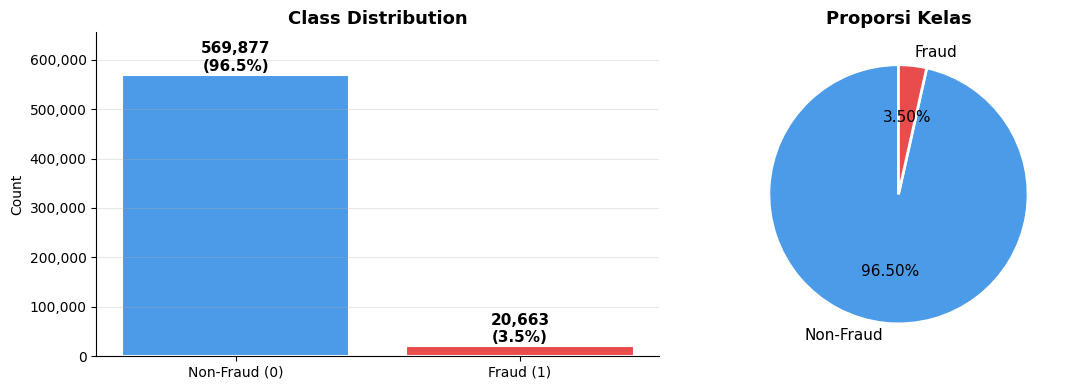

Plot disimpan → reports/figures/01_class_distribution.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
colors = ['#4C9BE8', '#E84C4C']
bars = axes[0].bar(['Non-Fraud (0)', 'Fraud (1)'], fraud_counts.values, color=colors, edgecolor='white', linewidth=1.5)
for bar, count, pct in zip(bars, fraud_counts.values, fraud_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
                 f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].set_title('Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
axes[0].set_ylim(0, fraud_counts[0] * 1.15)
axes[0].grid(axis='y', alpha=0.3)
axes[0].spines[['top', 'right']].set_visible(False)

# Pie chart
axes[1].pie(fraud_counts.values, labels=['Non-Fraud', 'Fraud'],
            colors=colors, autopct='%1.2f%%', startangle=90,
            textprops={'fontsize': 11}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporsi Kelas', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot disimpan → reports/figures/01_class_distribution.png')

---
## 1.6 Merge Transaction + Identity

In [11]:
df = transaction.merge(identity, on='TransactionID', how='left')

print(f'Setelah merge: {df.shape[0]:,} rows × {df.shape[1]} cols')
print(f'Transaksi dengan identity data: {identity["TransactionID"].nunique():,} ({identity["TransactionID"].nunique()/len(transaction)*100:.1f}%)')
print(f'Transaksi tanpa identity data : {len(transaction) - identity["TransactionID"].nunique():,}')

Setelah merge: 590,540 rows × 434 cols
Transaksi dengan identity data: 144,233 (24.4%)
Transaksi tanpa identity data : 446,307


In [12]:
# Apakah transaksi fraud lebih sering punya identity data?
has_identity = df['id_01'].notna().astype(int)
fraud_rate_by_identity = df.groupby(has_identity)['isFraud'].mean() * 100

print('Fraud rate berdasarkan ketersediaan identity data:')
print(f'  Tidak ada identity : {fraud_rate_by_identity[0]:.2f}%')
print(f'  Ada identity       : {fraud_rate_by_identity[1]:.2f}%')
print()
print('→ Transaksi dengan identity data cenderung memiliki fraud rate lebih tinggi')

Fraud rate berdasarkan ketersediaan identity data:
  Tidak ada identity : 2.09%
  Ada identity       : 7.85%

→ Transaksi dengan identity data cenderung memiliki fraud rate lebih tinggi


---
## 1.7 Quick Look: Fitur Kunci

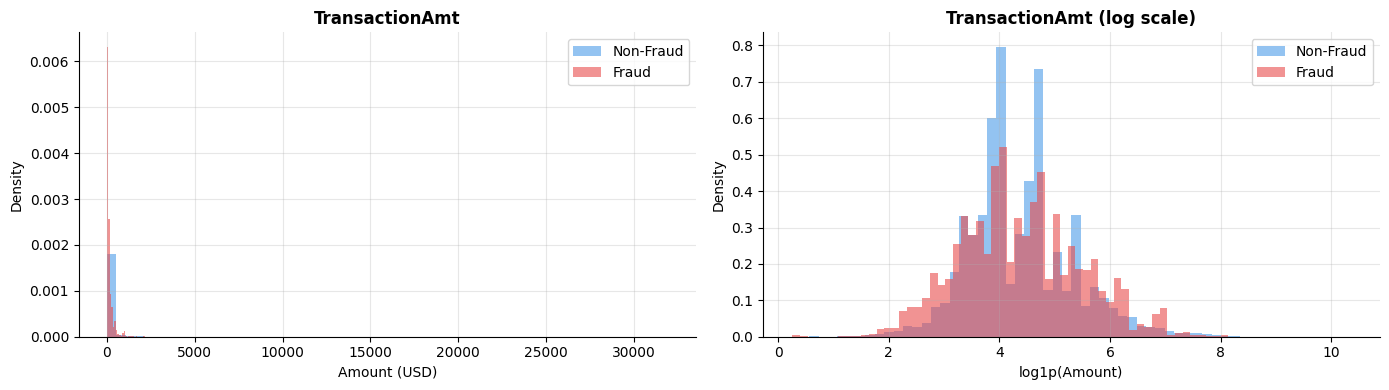

In [13]:
# TransactionAmt: distribusi fraud vs non-fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, log_scale, title in zip(axes, [False, True], ['TransactionAmt', 'TransactionAmt (log scale)']):
    for label, color in [(0, '#4C9BE8'), (1, '#E84C4C')]:
        subset = df[df['isFraud'] == label]['TransactionAmt']
        if log_scale:
            subset = np.log1p(subset)
        ax.hist(subset, bins=60, alpha=0.6, color=color,
                label='Non-Fraud' if label == 0 else 'Fraud', density=True)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('log1p(Amount)' if log_scale else 'Amount (USD)')
    ax.set_ylabel('Density')
    ax.legend()
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/01_transaction_amount.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# ProductCD: fraud rate per kategori
product_stats = df.groupby('ProductCD').agg(
    total=('isFraud', 'count'),
    fraud=('isFraud', 'sum')
).assign(fraud_rate=lambda x: x['fraud'] / x['total'] * 100).sort_values('fraud_rate', ascending=False)

print('Fraud rate per ProductCD:')
print(product_stats.to_string())

Fraud rate per ProductCD:
            total  fraud  fraud_rate
ProductCD                           
C           68519   8008     11.6873
S           11628    686      5.8996
H           33024   1574      4.7662
R           37699   1426      3.7826
W          439670   8969      2.0399


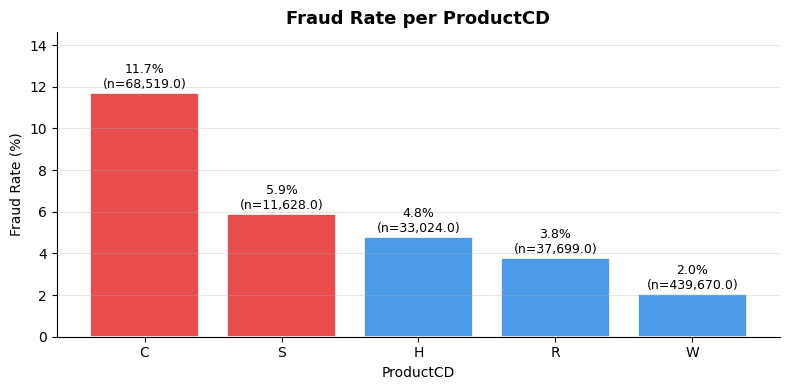

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(product_stats.index, product_stats['fraud_rate'],
              color=['#E84C4C' if r > 5 else '#4C9BE8' for r in product_stats['fraud_rate']],
              edgecolor='white', linewidth=1.2)

for bar, (idx, row) in zip(bars, product_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{row["fraud_rate"]:.1f}%\n(n={row["total"]:,})',
            ha='center', va='bottom', fontsize=9)

ax.set_title('Fraud Rate per ProductCD', fontsize=13, fontweight='bold')
ax.set_xlabel('ProductCD')
ax.set_ylabel('Fraud Rate (%)')
ax.set_ylim(0, product_stats['fraud_rate'].max() * 1.25)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/01_fraud_rate_productcd.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# Card type: fraud rate
for col in ['card4', 'card6']:
    stats = df.groupby(col)['isFraud'].agg(['count', 'mean']).rename(columns={'mean': 'fraud_rate'})
    stats['fraud_rate'] = (stats['fraud_rate'] * 100).round(2)
    print(f'\n{col}:')
    print(stats.sort_values('fraud_rate', ascending=False).to_string())


card4:
                   count  fraud_rate
card4                               
discover            6651      7.7300
visa              384767      3.4800
mastercard        189217      3.4300
american express    8328      2.8700

card6:
                  count  fraud_rate
card6                              
credit           148986      6.6800
debit            439938      2.4300
charge card          15      0.0000
debit or credit      30      0.0000


---
## 1.8 Missing Value Overview (Seluruh Dataset)

In [17]:
missing = df.isnull().mean().sort_values(ascending=False)
missing_df = missing[missing > 0].reset_index()
missing_df.columns = ['feature', 'missing_rate']

print(f'Kolom dengan missing values: {len(missing_df)} dari {len(df.columns)}')
print(f'  > 90% missing: {(missing_df["missing_rate"] > 0.9).sum()}')
print(f'  > 50% missing: {(missing_df["missing_rate"] > 0.5).sum()}')
print(f'  > 10% missing: {(missing_df["missing_rate"] > 0.1).sum()}')

Kolom dengan missing values: 414 dari 434
  > 90% missing: 12
  > 50% missing: 214
  > 10% missing: 322


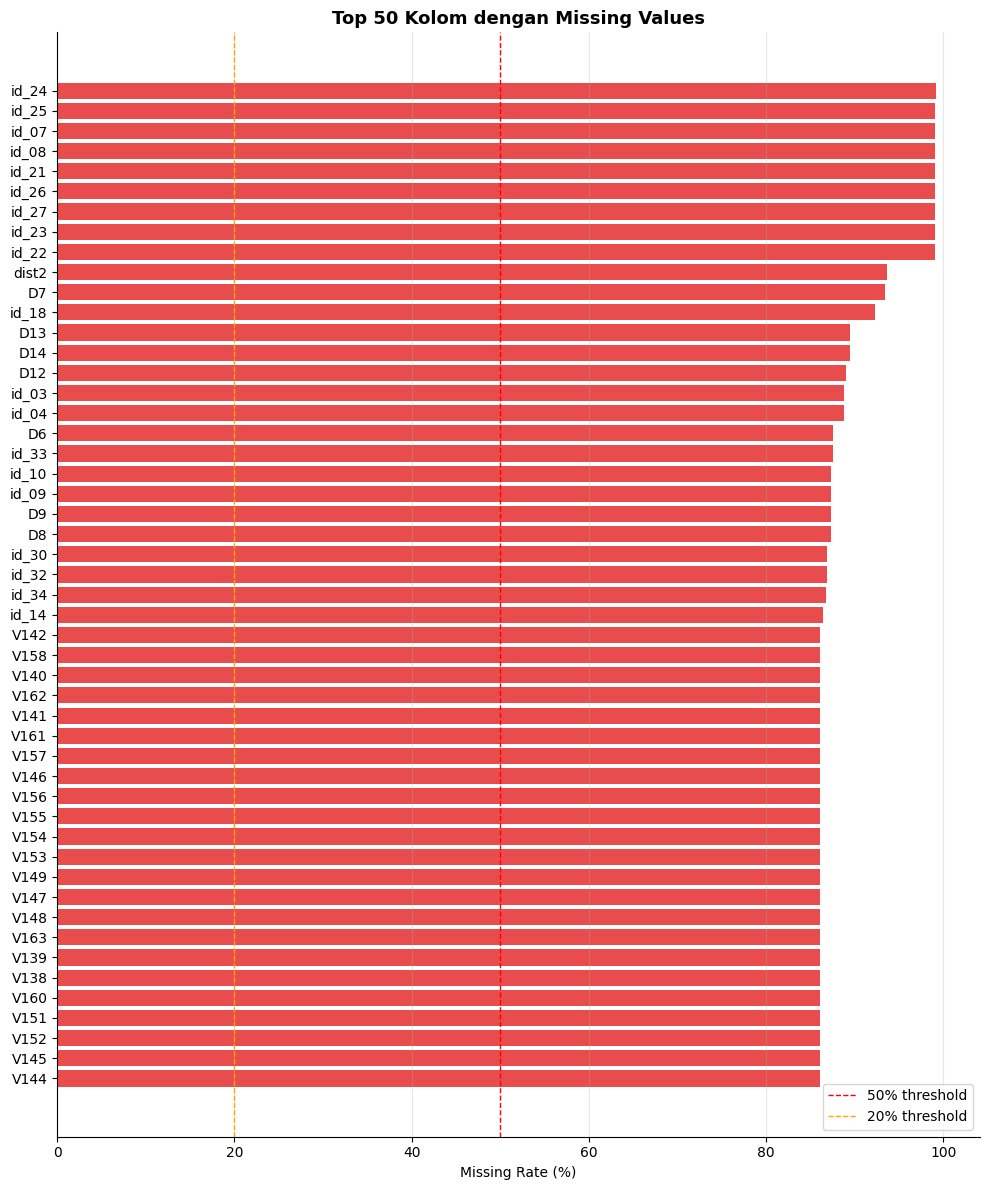

In [18]:
# Visualisasi missing rate — top 50 kolom
top_missing = missing_df.head(50)

fig, ax = plt.subplots(figsize=(10, 12))
colors = ['#E84C4C' if r > 0.5 else '#F4A261' if r > 0.2 else '#4C9BE8'
          for r in top_missing['missing_rate']]
ax.barh(top_missing['feature'], top_missing['missing_rate'] * 100, color=colors)
ax.axvline(50, color='red', linestyle='--', linewidth=1, label='50% threshold')
ax.axvline(20, color='orange', linestyle='--', linewidth=1, label='20% threshold')
ax.set_xlabel('Missing Rate (%)')
ax.set_title('Top 50 Kolom dengan Missing Values', fontsize=13, fontweight='bold')
ax.legend()
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/figures/01_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 1.9 Ringkasan Temuan (Dataset Audit)

| Aspek | Temuan |
|-------|--------|
| **Ukuran data** | 590,540 transaksi × 434 kolom (setelah merge) |
| **Target imbalance** | ~3.5% fraud — sangat imbalanced, perlu strategi khusus |
| **Identity coverage** | ~43% transaksi punya identity data |
| **Missing values** | Banyak kolom V-features & identity >50% missing |
| **ProductCD** | Kategori tertentu punya fraud rate jauh lebih tinggi |
| **TransactionAmt** | Distribusi fraud & non-fraud overlap — tidak mudah dipisah secara amount saja |

**Next step → Notebook 02: EDA & Data Quality** — analisis lebih dalam per grup fitur